# Predictive Coding in JAX 🤖🧠

This notebook shows how predictive coding (PC) can be implemented in JAX. Any place you see a **Task** you should complete it. Any place you see ❓ **Questions you may be asked**, you should think about it because it may come up in a discussion!

The aim of this notebook is to give you a flavor of the type of work done in the [ARNI](https://arni-institute.org/) Biological Learning Working Group. The code below is a stripped-down copy of what actually runs in our research codebase, so if you can follow this notebook you can read the real thing.

We will build and train a feedforward neural network on the MNIST dataset using PC (without backpropagation).

JAX is basically NumPy but with automatic differentiation and vectorization built in. To learn more about JAX, you can take a look at their quickstart guide [here](https://docs.jax.dev/en/latest/101/index.html#jax-101), but we will explain some things along the way. We will also use: (i) [Equinox](https://docs.kidger.site/equinox/), which allows you to define neural nets with PyTorch-like syntax; and (ii) [Optax](https://optax.readthedocs.io/en/latest/index.html), which provides optimizers such as gradient descent and Adam.

# Task 1: Setting up the environment
Install any necessary dependencies to run the next cell. You might consider using a virtual environment manager such as [`uv`](https://docs.astral.sh/uv/).

**❓Questions you may be asked:**
- What is a virtual environment?
- Why is it useful?

In [1]:
import warnings
from collections.abc import Callable

import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import optax
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

warnings.simplefilter("ignore")

## Hyperparameters

We define some hyperparameters related to the data, network, optimizers, etc.

In [2]:
SEED = 42

INPUT_DIM, OUTPUT_DIM = 28 * 28, 10
HIDDEN_SIZE = 300
N_LAYERS = 3  # number of weight layers

ACTIVITY_LR = 0.1 # settling / inference learning rate
INFERENCE_STEPS = 20 # number of inference steps per batch

PARAM_LR = 1e-3 # parameter learning rate
BATCH_SIZE = 64

TEST_EVERY = 50 # evaluate every 50 batches
N_TRAIN_ITERS = 500

## Dataset

Some utils to fetch MNIST.

In [3]:
def get_mnist_loaders(batch_size):
    train_data = MNIST(train=True, normalize=True)
    test_data = MNIST(train=False, normalize=True)
    train_loader = DataLoader(
        dataset=train_data,
        batch_size=batch_size,
        shuffle=True,
        drop_last=True
    )
    test_loader = DataLoader(
        dataset=test_data,
        batch_size=batch_size,
        shuffle=True,
        drop_last=True
    )
    return train_loader, test_loader


class MNIST(datasets.MNIST):
    def __init__(self, train, normalize=True, save_dir="data"):
        if normalize:
            transform = transforms.Compose(
                [
                    transforms.ToTensor(),
                    transforms.Normalize(
                        mean=(0.1307), std=(0.3081)
                    )
                ]
            )
        else:
            transform = transforms.Compose([transforms.ToTensor()])
        super().__init__(save_dir, download=True, train=train, transform=transform)

    def __getitem__(self, index):
        img, label = super().__getitem__(index)
        img = torch.flatten(img)
        label = one_hot(label)
        return img, label


def one_hot(labels, n_classes=10):
    arr = torch.eye(n_classes)
    return arr[labels]

## Predictive Coding 101
Predictive coding (PC) is an algorithm for *inference* and *learning* that optimizes a prediction-error energy function [[rao1999](https://www.nature.com/articles/nn0199_79), [whittington2017](https://direct.mit.edu/neco/article/29/5/1229/8261/An-Approximation-of-the-Error-Backpropagation), [pinchetti2025](https://arxiv.org/abs/2407.01163)]. It is an alternative to backpropagation and uses local Hebbian learning rules to update its weights, which only requires pre- and postsynaptic activity, making it a spatially local algorithm [[bogacz2017](https://pmc.ncbi.nlm.nih.gov/articles/PMC5341759/)]. In its most common form, each layer of the network has a latent variable $\boldsymbol{z}$ that is optimized to minimize a global energy function—a process called inference (also referred to algorithmically as settling). Once the latent variables have settled, the weights are updated to minimize the same energy function—learning. A standard PC assumption is that each layer's latent is a Gaussian random variable with a mean given by the output of the previous layer. This allows one to write down a probabilistic model and derive a resulting energy function from the log probability. For example, the probability distribution, and resulting energy function, for an $\ell$-layer feedforward network with latents $(\boldsymbol{z}_0=\boldsymbol{x}), \boldsymbol{z}_1, \ldots, (\boldsymbol{z}_{\ell}=\boldsymbol{y})$, weights $\boldsymbol{W}_1, \ldots, \boldsymbol{W}_{\ell}$, and activation function $g$ are
$$
\begin{gather}
p(\boldsymbol{z}_0, \boldsymbol{z}_1, \ldots, \boldsymbol{z}_{\ell}) = p(\boldsymbol{z}_1\mid \boldsymbol{z}_0) \prod_{i=2}^{\ell} p(\boldsymbol{z}_i \mid \boldsymbol{z}_{i-1}),
\quad
p(\boldsymbol{z}_i \mid \boldsymbol{z}_{i-1}) = \mathcal{N}(\boldsymbol{z}_i; \boldsymbol{W}_i g(\boldsymbol{z}_{i-1}), \mathbf{I}), \\
E(\boldsymbol{z}_0, \boldsymbol{z}_1, \ldots, \boldsymbol{z}_{\ell}) = -\log p(\boldsymbol{z}_0, \boldsymbol{z}_1, \ldots, \boldsymbol{z}_{\ell}) = \frac12\sum_{i=1}^{\ell} \lVert \boldsymbol{z}_i - \boldsymbol{W}_i g(\boldsymbol{z}_{i-1})\rVert^2.
\end{gather}
$$
Note that we have denoted the data input as $\boldsymbol{z}_0=\boldsymbol{x}$ and its label as $\boldsymbol{z}_{\ell}=\boldsymbol{y}$.

We are now going to code this up in JAX.

In [4]:
class FeedforwardPCModel(eqx.Module):
    # Each layer is Sequential([activation, Linear]): a PRE-activation layer.
    layers: list[eqx.Module]
    act = eqx.nn.Identity()
    def __init__(
            self,
            key,
            *,
            input_size,
            hidden_size,
            output_size,
            activation_fn,
            input_activation_fn=act,
            n_layers=2,
            use_bias=True,
    ):
        keys = jr.split(key, n_layers)
        widths = [input_size] + [hidden_size] * (n_layers - 1) + [output_size]

        layers = []
        for i in range(n_layers):
            act = input_activation_fn if i == 0 else activation_fn
            act_layer = act if isinstance(
                act, eqx.Module) else _StaticActivation(act)
            linear = eqx.nn.Linear(widths[i],
                                   widths[i + 1],
                                   key=keys[i],
                                   use_bias=use_bias)
            layers.append(eqx.nn.Sequential([act_layer, linear]))

        self.layers = layers

    def __call__(self, x):
        # feedforward pass for a SINGLE example
        for layer in self.layers:
            x = layer(x)
        return x

    def __getitem__(self, i):
        # Implements indexing so PC loops can write
        # err = activities[l] - model[l](activities[l - 1]).
        return self.layers[i]

    def __len__(self):
        return len(self.layers)


class _StaticActivation(eqx.Module):
    # Not important to understand this class for this tutorial.
    # Wraps a bare callable (e.g. jax.nn.tanh) as an eqx.Module whose function
    # lives in static metadata, not as a pytree leaf.
    fn: Callable = eqx.field(static=True)

    def __call__(self, x, *, key=None):
        return self.fn(x)

Let's instantiate it. JAX uses explicit random number generators (see the [docs](https://jax.readthedocs.io/en/latest/random-numbers.html)): the model takes a `key` and splits it once per layer. Printing an Equinox module shows its pytree structure. The only arrays are the `weight`s and `bias`es.

In [5]:
key = jr.PRNGKey(SEED)

model = FeedforwardPCModel(
    key,
    input_size=INPUT_DIM,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_DIM,
    activation_fn=jax.nn.tanh,
    n_layers=N_LAYERS,
)
model

FeedforwardPCModel(
  layers=[
    Sequential(
      layers=(
        Identity(),
        Linear(
          weight=f32[300,784],
          bias=f32[300],
          in_features=784,
          out_features=300,
          use_bias=True
        )
      )
    ),
    Sequential(
      layers=(
        _StaticActivation(fn=<PjitFunction of <function tanh at 0x10f41d6c0>>),
        Linear(
          weight=f32[300,300],
          bias=f32[300],
          in_features=300,
          out_features=300,
          use_bias=True
        )
      )
    ),
    Sequential(
      layers=(
        _StaticActivation(fn=<PjitFunction of <function tanh at 0x10f41d6c0>>),
        Linear(
          weight=f32[10,300],
          bias=f32[10],
          in_features=300,
          out_features=10,
          use_bias=True
        )
      )
    )
  ]
)

The model acts on a single example. To run it on a batch we vectorize it with `jax.vmap`, one of the core JAX transforms (see the [docs](https://jax.readthedocs.io/en/latest/automatic-vectorization.html)). `vmap` adds a leading batch axis to every input and output without us touching the model code. Let's check both on some MNIST data.

In [6]:
train_loader, test_loader = get_mnist_loaders(BATCH_SIZE)
img_batch, label_batch = next(iter(train_loader))

# we need to turn the torch.Tensor data into numpy arrays for jax
img_batch, label_batch = img_batch.numpy(), label_batch.numpy()
print(f"image batch: {img_batch.shape}, label batch: {label_batch.shape}")

# a single example
print(f"model(x) for one example: {model(img_batch[0]).shape}")

# the whole batch: vmap adds the batch axis for us
print(f"vmap(model)(X) for the batch: {jax.vmap(model)(img_batch).shape}")

image batch: (64, 784), label batch: (64, 10)
model(x) for one example: (10,)
vmap(model)(X) for the batch: (64, 10)


## PC energy and optimization

Recall that input $\boldsymbol{z}_0 = \boldsymbol{x}$ is clamped below the first layer and the target $\boldsymbol{z}_{\ell} = \boldsymbol{y}$ is clamped at the output of the last layer. *Inference* will optimize all the latent variables (i.e., the activities) $\boldsymbol{z}_1, \ldots, \boldsymbol{z}_{\ell-1}$ to minimize the energy function. *Learning* will then update the weights $\boldsymbol{W}_1, \ldots, \boldsymbol{W}_{\ell}$ to minimize the same energy function *after* inference has settled the latents.

\begin{equation}
    \text{Inference:} \quad \Delta \boldsymbol{z}_i \propto - \frac{\partial E}{\partial \boldsymbol{z}_i}
\end{equation}

\begin{equation}
    \text{Learning:} \quad \Delta \boldsymbol{W}_i \propto - \frac{\partial E}{\partial \boldsymbol{W}_i}
\end{equation}

The energy function is a sum of squared errors between each layer's latent and the output of the previous layer passed through the weights and activation function (the energy $E$ above). See [Figure 1 here](https://toddmorrill.github.io/machine%20learning/unsupervised-predictive-coding/) for a diagram of the layerwise circuit.

Let's implement `energy_fn`, which takes the model (i.e., the weights and biases), a list of activities, and one input/output pair, and walks the layers accumulating the squared error at each. Note:
* It is written for a **single example**. Batching comes next.
* It returns a tuple `(energy, aux)`. `aux` is a dictionary of per-layer energies that we will use to monitor inference.
* Python indexes from 0 while the equations index from 1, so `activities[0]` is $\boldsymbol{z}_1$, and `activities[-1]` occupies the slot of $\boldsymbol{z}_\ell$. Since $\boldsymbol{z}_\ell = \boldsymbol{y}$ is clamped, `energy_fn` ignores that entry and uses `output` instead; `activities[-1]`, the feedforward prediction of $\boldsymbol{y}$, is what we use at test time.
* The per-layer keys (`energy/layer_<i>`, `energy/output`) are logged for inspection.

In [7]:
def energy_fn(model, activities, input_, output, record_aux_details=True):
    # Layer-wise PC energy for a SINGLE example.
    # Layer 0 predicts from input_; interior layers predict from the previous
    # activity; the final layer's prediction is compared against output.
    last_idx = len(model) - 1
    energies = []
    aux = {}
    for layer_idx, layer in enumerate(model.layers):
        if layer_idx == 0:
            pred = layer(input_)
            err = activities[layer_idx] - pred
            key = f'energy/layer_{layer_idx}'
        elif layer_idx == last_idx:
            pred = layer(activities[layer_idx - 1])
            err = output - pred
            key = 'energy/output'
        else:
            pred = layer(activities[layer_idx - 1])
            err = activities[layer_idx] - pred
            key = f'energy/layer_{layer_idx}'
        energies.append(0.5 * jnp.sum(err ** 2))
        if record_aux_details:
            aux[key] = energies[-1]
    return sum(energies), aux

**❓Questions you may be asked:**
- Why isn't this backpropagation?

ANSWER:
This is not standard backprop because of the hidden-state settling process. During hidden state settling, the model weights are held fixed while the hidden activities settle. This layer-local representation optimization is distinct from pure, global backprop. At each settling step, we compute the activity gradients and use them to update the hidden states. Finally, the settled activities are held fixed and the gradient is derived with respect to the weights and used to update them. JAX supplies the derivatives for these separate stages, but the settling dynamics themselves are not part of a single end-to-end backpropagation graph.

### Batching the energy with `vmap`

To evaluate the energy on a batch we vectorize `energy_fn` with `jax.vmap`. The `in_axes` argument says, for each positional argument, which axis the batch axis is:

| argument | `in_axes` | meaning |
|---|---|---|
| `model` | `None` | shared across the batch, not batched |
| `activities` | `0` | a *list* of arrays; `vmap` maps over pytrees, so every array in the list gets its leading axis batched |
| `input_`, `output` | `0` | the leading axis is the batch |
| `record_aux_details` | `None` | a static Python bool, passed through unchanged |

`batched_energy_fn` therefore returns one energy **per example** (shape `(batch,)`) plus an `aux` dict whose values are also per example. We then reduce over the batch in two different ways:
* **`batched_energy_sum`** is what we differentiate with respect to the **activities**. Each example's activities appear only in its own energy term, so with a *sum* the gradient for example $i$ is exactly $\partial E_i / \partial \mathbf{z}_{\ell,i}$: the prediction error of that example, independent of how many other examples are in the batch.
* **`batched_energy_mean`** is what we differentiate with respect to the **parameters**. The weights are shared by every example, so their gradient sums contributions from the whole batch; dividing by the batch size makes the parameter gradient (and hence the learning rate) invariant to the batch size.

In [8]:
def batched_energy_fn(model, activities, input_, output, energy_fn_, record_aux_details=True):
    # vmap a single-example energy_fn over the batch dimension
    return jax.vmap(energy_fn_, in_axes=(None, 0, 0, 0, None))(
        model, activities, input_, output, record_aux_details)


def batched_energy_sum(model, activities, input_, output, energy_fn_, record_aux_details=True):
    # sum-reduce per-example energies (preserves per-example activity grads)
    per_ex, aux = batched_energy_fn(model, activities, input_, output, energy_fn_, record_aux_details)
    return jnp.sum(per_ex), jax.tree_util.tree_map(jnp.sum, aux)


def batched_energy_mean(model, activities, input_, output, energy_fn_, record_aux_details=True):
    # mean-reduce per-example energies (batch-size invariant param grads)
    per_ex, aux = batched_energy_fn(model, activities, input_, output, energy_fn_, record_aux_details)
    return jnp.mean(per_ex), jax.tree_util.tree_map(jnp.mean, aux)

### Initializing the activities

The last ingredient is an initial value for the activities. We use a feedforward pass: `activities[l] = model[l](activities[l - 1])`, starting from the input.

❓ **Questions you may be asked**: Can you think of other ways of initializing the activities? What are the trade-offs?

Zeros or random values. With zeros, every image starts with the same hidden states, which is simple and deterministic. Random values give different starting points, but we’d have to choose their scale and control the added noise.


In [9]:
def init_activities_with_ffwd(model, input_):
    # feedforward init for a SINGLE example:
    # activities[l] = layer_l(activities[l - 1]), starting from input_
    activities = [model[0](input_)]
    for l in range(1, len(model)):
        activities.append(model[l](activities[l - 1]))
    return activities

Let's test it on the MNIST batch from before. For a single example we call the function directly; for the batch we `vmap` it with `in_axes=(None, 0)`: the model is shared, the input is batched. Note how every activity acquires a leading batch axis.

# Task 2: `vmap` sanity check. Initialize the activities for a batch of MNIST images. The code below is not implemented yet. Implement it and check that the shapes of the activities are as expected.

In [10]:
# a single example
activities_one = init_activities_with_ffwd(model, img_batch[0])
for l, z in enumerate(activities_one):
    print(f"single example, activity z_{l}: {z.shape}")

def init_activities_with_ffwd_batch(model, input_):
    # feedforward init for a BATCH of examples:
    # activities[l] = layer_l(activities[l - 1]), starting from input_    
    return jax.vmap(init_activities_with_ffwd, in_axes=(None, 0))(
        model, input_)        
activities = init_activities_with_ffwd_batch(model, img_batch)

for l, z in enumerate(activities):
    print(f"batched example, activity z_{l}: {z.shape}")

single example, activity z_0: (300,)
single example, activity z_1: (300,)
single example, activity z_2: (10,)
batched example, activity z_0: (64, 300)
batched example, activity z_1: (64, 300)
batched example, activity z_2: (64, 10)


Ok so now we have everything to test our PC energy function: model, activities, and some data. We look at the per-example energies first, then at the batch mean broken down per layer.

In [11]:
per_example_energy, _ = batched_energy_fn(model, activities, img_batch, label_batch, energy_fn)
print(f"per-example energies: shape {per_example_energy.shape}, first five: {per_example_energy[:5]}")

energy, aux = batched_energy_mean(model, activities, img_batch, label_batch, energy_fn)
print(f"\nbatch-mean energy: {energy:.4f}")
for name, value in aux.items():
    print(f"  {name}: {value:.4f}")

per-example energies: shape (64,), first five: [0.5554759  0.6859963  0.5422106  0.59177667 0.57925206]

batch-mean energy: 0.6021
  energy/layer_0: 0.0000
  energy/layer_1: 0.0000
  energy/output: 0.6021


It works! Notice that at the feedforward initialization *every hidden-layer energy is exactly zero*: each activity was set to precisely what the layer below predicts. All of the energy sits in the output term, the mismatch between the network's prediction and the one-hot label. Inference will now spread this error back through the hidden activities.

## Energy gradients

How do we minimize the PC energy we defined above (the energy $E$)? We do this in two phases: first with respect to the activities (inference) and then with respect to the weights (learning).

We are going to use autodiff, which JAX embeds by design (see the [docs](https://jax.readthedocs.io/en/latest/notebooks/autodiff_cookbook.html)). If you're familiar with PyTorch, you are probably used to `loss.backward()` for this. JAX, on the other hand, is functional (as opposed to object-oriented): `jax.grad(f, argnums=1)` *returns a new function* that computes the gradient of `f` with respect to its second argument.

**Technical note**: for the parameters we use Equinox's `filter_grad` rather than JAX's native `grad`. The model pytree contains things that are not arrays (the static activation functions), and `filter_grad` differentiates only with respect to the array leaves of its first argument, while `grad` alone would throw an error.

In [12]:
# "the gradient of the (summed) energy with respect to the 2nd argument (the activities)"
def compute_activity_grad(model, activities, input_, output, record_aux_details=True):
    # per-example activity gradient of the batch-SUMMED energy
    return jax.grad(batched_energy_sum, argnums=1, has_aux=True)(
        model, activities, input_, output, energy_fn, record_aux_details)


# for parameters, the only differences are: we differentiate the batch-MEAN energy...
# ...with respect to the 1st argument (the model), skipping its non-array leaves

def compute_param_grad(model, activities, input_, output, record_aux_details=True):
    # batch-averaged parameter gradient
    return eqx.filter_grad(batched_energy_mean, has_aux=True)(
        model, activities, input_, output, energy_fn, record_aux_details)

Let's test the activity gradient. Besides the shapes, look at the *size* of the gradient at each layer, right at the feedforward initialization.

In [13]:
dEdzs, aux = compute_activity_grad(model, activities, img_batch, label_batch)
for l, dEdz in enumerate(dEdzs):
    print(f"activity gradient dE/dz_{l}: shape {dEdz.shape}, mean |dE/dz| = {jnp.abs(dEdz).mean():.4f}")

activity gradient dE/dz_0: shape (64, 300), mean |dE/dz| = 0.0000
activity gradient dE/dz_1: shape (64, 300), mean |dE/dz| = 0.0290
activity gradient dE/dz_2: shape (64, 10), mean |dE/dz| = 0.0000


❓ **Challenge Question, not mandatory**: Only one activity has a non-zero gradient at initialization, and it is not the last one. Explain both facts using the energy: which terms does each $\boldsymbol{z}_\ell$ appear in, and which of those are non-zero at the feedforward initialization? What does this imply about how many inference steps are needed for the output error to reach the first layer?

Now the parameter gradient. `filter_grad` returns a pytree with the same structure as the model: gradient arrays for the weights and biases, and nothing for the static parts. The same reasoning as above tells you which layers get a non-zero gradient at initialization, and hence why inference has to run *before* learning.

ANSWER: The hidden activities are initialized by running the network forward once, so they match their layers’ predictions and their prediction errors are zero. The first hidden activity affects the layer 0 and layer 1 errors. The second affects the layer 1 and output errors. However, the output still differs from the target label. This label error first changes the last hidden activity. On the next update, that change propagates backward and begins changing the first hidden activity.

The last entry in activities has zero gradient because energy_fn never uses it. It uses the label in that position instead.

In [14]:
param_grads, aux = compute_param_grad(model, activities, img_batch, label_batch)
for l, layer_grad in enumerate(param_grads.layers):
    linear_grad = layer_grad.layers[1]  # Sequential([activation, Linear]) -> the Linear
    print(f"layer {l}: dE/dW {linear_grad.weight.shape}, dE/db {linear_grad.bias.shape}, "
          f"mean |dE/dW| = {jnp.abs(linear_grad.weight).mean():.2e}")

layer 0: dE/dW (300, 784), dE/db (300,), mean |dE/dW| = 0.00e+00
layer 1: dE/dW (300, 300), dE/db (300,), mean |dE/dW| = 0.00e+00
layer 2: dE/dW (10, 300), dE/db (10,), mean |dE/dW| = 1.62e-02


## Updates

Before putting everything together, let's wrap our gradients into update functions. This will also allow us to use JAX's `jit` primitive (here Equinox's `filter_jit`, which again treats the non-array parts of the model as static), which compiles a function the first time it is called so that subsequent calls run much faster (see the [docs](https://jax.readthedocs.io/en/latest/jit-compilation.html) for more details).

These functions take an Optax optimizer and its state in addition to the model, activities, and data. Optax optimizers are pure functions: `optim.update` returns the updates *and a new state*, and `eqx.apply_updates` adds the updates to the pytree being optimized (a list of arrays for the activities, the model for the parameters).

In [15]:
@eqx.filter_jit
def update_activities(model, activities, x_optim, x_opt_state, input_, output, record_aux_details=True):
    activity_grads, aux = compute_activity_grad(model, activities, input_, output, record_aux_details)
    updates, x_opt_state = x_optim.update(activity_grads, x_opt_state, params=activities)
    activities = eqx.apply_updates(activities, updates)
    return activities, x_opt_state, aux


# note that the only difference with the above function is...
# ...the variable we are updating (parameters vs. activities)
@eqx.filter_jit
def update_params(model, activities, p_optim, p_opt_state, input_, output, record_aux_details=True):
    param_grads, aux = compute_param_grad(model, activities, input_, output, record_aux_details)
    updates, p_opt_state = p_optim.update(param_grads, p_opt_state, params=model)
    model = eqx.apply_updates(model, updates)
    return model, p_opt_state, aux

Let's watch inference happen. We run a handful of activity updates with plain gradient descent and print the per-layer energies after each step (this is what `aux` is for).

In [16]:
x_optim = optax.sgd(ACTIVITY_LR)
x_opt_state = x_optim.init(activities)

settled = activities
for step in range(5):
    settled, x_opt_state, _ = update_activities(
        model, settled, x_optim, x_opt_state, img_batch, label_batch)
    total, per_layer = batched_energy_mean(model, settled, img_batch, label_batch, energy_fn)
    print(f"step {step + 1}: total energy {total:.4f}  |  "
          + "  ".join(f"{k.split('/')[1]}: {v:.2e}" for k, v in per_layer.items()))

step 1: total energy 0.5685  |  layer_0: 0.00e+00  layer_1: 1.80e-03  output: 5.67e-01
step 2: total energy 0.5429  |  layer_0: 3.97e-06  layer_1: 6.14e-03  output: 5.37e-01
step 3: total energy 0.5233  |  layer_0: 2.94e-05  layer_1: 1.19e-02  output: 5.11e-01
step 4: total energy 0.5080  |  layer_0: 9.74e-05  layer_1: 1.82e-02  output: 4.90e-01
step 5: total energy 0.4960  |  layer_0: 2.25e-04  layer_1: 2.47e-02  output: 4.71e-01


You can see the output error being pushed down into the hidden layers one layer per step, while the total energy decreases: `layer_1` becomes non-zero after the first update, `layer_0` only after the second.

In practice, we do not run this Python loop—we use `jax.lax.scan`, JAX's compiled `for` loop (see the [docs](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html)). `scan` takes a body function `(carry, _) -> (carry, output)`, threads the `carry` (here the activities and the optimizer state) through `T` iterations, and stacks the per-iteration outputs (here the `aux` energies). The result is a single compiled program per batch: initialize the activities, settle for `T` steps, then update the parameters once.

In [17]:
@eqx.filter_jit
def train_step(model, input_, output, p_optim, p_opt_state, x_optim, T, record_aux_details=True):
    # one batch: feedforward-initialize, settle for T steps, update the parameters once

    # inference: initialize the activities per example (vmap over the batch)...
    activities = jax.vmap(init_activities_with_ffwd, in_axes=(None, 0))(model, input_)
    x_opt_state = x_optim.init(activities)

    # ...then relax them for T steps
    def settle_body(carry, _):
        activities, x_opt_state = carry
        activities, x_opt_state, aux = update_activities(
            model, activities, x_optim, x_opt_state, input_, output, record_aux_details)
        return (activities, x_opt_state), aux

    (activities, _), aux_scan = jax.lax.scan(
        settle_body, (activities, x_opt_state), None, length=T)

    # energy of the settled state, i.e. what the parameter update sees
    energy, _ = batched_energy_mean(model, activities, input_, output, energy_fn, False)

    # learning: one parameter update at the settled activities
    model, p_opt_state, _ = update_params(
        model, activities, p_optim, p_opt_state, input_, output, record_aux_details=False)

    return {
        "model": model,
        "p_opt_state": p_opt_state,
        "activities": activities,
        "energy": energy,
        "aux": aux_scan,  # per-layer energies along the settling trajectory, each of shape (T,)
    }

# Task 3: Plot the per-layer energies along the settling trajectory for 50 settling steps.
Let's run a single training step and look at the energies along the settling trajectory. Since `scan` stacks the per-step `aux`, each entry is a vector of length `T`: the energy of that layer *before* each of the `T` updates.
The code below is not implemented yet.

In [18]:
p_optim = optax.sgd(PARAM_LR)
p_opt_state = p_optim.init(model.layers)
x_optim = optax.sgd(ACTIVITY_LR)
x_opt_state = x_optim.init(activities)
step_1_out = train_step(
    model = model,
    input_ = img_batch,
    output = label_batch,
    p_optim = p_optim,
    p_opt_state = p_opt_state,
    x_optim = x_optim,
    T = 50
)

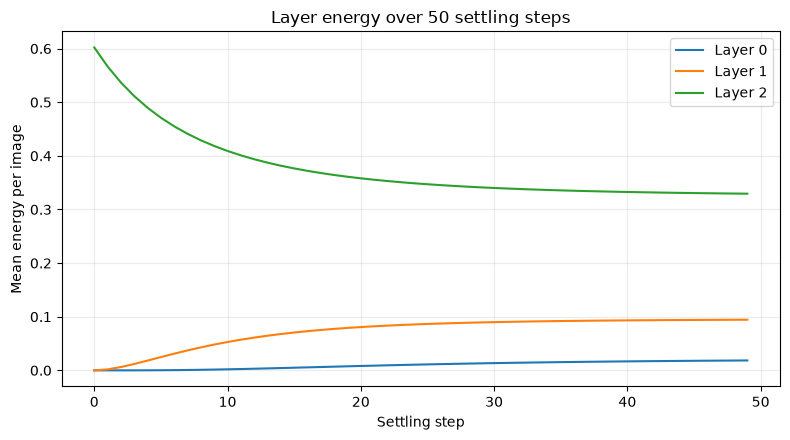

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, energies in enumerate(step_1_out["aux"].values()):
    ax.plot(
        range(len(energies)),
        energies / BATCH_SIZE,
        label=f"Layer {i}",
    )

ax.set_xlabel("Settling step")
ax.set_ylabel("Mean energy per image")
ax.set_title("Layer energy over 50 settling steps")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


❓**Questions you may be asked**: What do you observe in this trace? Is there anything problematic about the energy for layer 0?

The energy for the hidden layers move to satisy the minimization objective. The lower layers, those closer to the raw inputs, increase their hidden state error, while the output error drops by more, so the total energy goes down.

Layer 0 error starts increasing later and stays much smaller. That could mean the early weights get a weak learning signal. We should look at the magnitude of the gradients flowing into it and tie those to its weight changes, and see how those diagnostics relate to the layer energy in the plot.

## Putting everything together: training and testing

Now that we have a training step, we need a way to loop over the data and a way to evaluate.

Prediction is simply the feedforward pass: as discussed, `activities[-1]` from the feedforward initialization is the network's prediction of the label, and it is exactly `model(x)`. We `vmap` and `jit` it.

In [20]:
@eqx.filter_jit
def predict(model, input_):
    return jax.vmap(model)(input_)


def evaluate(model, test_loader):
    avg_test_acc = 0.0
    for img_batch, label_batch in test_loader:
        img_batch, label_batch = img_batch.numpy(), label_batch.numpy()
        preds = predict(model, img_batch)
        test_acc = jnp.mean(
            jnp.argmax(label_batch, axis=1) == jnp.argmax(preds, axis=1)
        ) * 100
        avg_test_acc += test_acc
    return avg_test_acc / len(test_loader)


def train(model, activity_lr, inference_steps, param_lr, batch_size,
          test_every, n_train_iters):
    # optimizers for the activities (plain gradient descent) and the parameters (Adam)
    x_optim = optax.sgd(activity_lr)
    p_optim = optax.adam(param_lr)
    p_opt_state = p_optim.init(eqx.filter(model, eqx.is_array))

    train_loader, test_loader = get_mnist_loaders(batch_size)
    train_loader = infinite_loader(train_loader)  # make it infinite so we can break on n_train_iters
    for train_iter, (img_batch, label_batch) in enumerate(train_loader):
        img_batch, label_batch = img_batch.numpy(), label_batch.numpy()

        # inference + learning, all inside one compiled step
        out = train_step(model,
                         img_batch,
                         label_batch,
                         p_optim,
                         p_opt_state,
                         x_optim,
                         T=inference_steps,
                         record_aux_details=False)
        model, p_opt_state = out["model"], out["p_opt_state"]

        if (train_iter + 1) % test_every == 0:
            avg_test_acc = evaluate(model, test_loader)
            print(
                f"Train iter {train_iter + 1}, train energy={out['energy']:.4f}, "
                f"avg test accuracy={avg_test_acc:.2f}%")
        if (train_iter + 1) >= n_train_iters:
            break

    return model

def infinite_loader(dataloader):
    while True:
        yield from dataloader

## Run

Let's test our implementation.

In [21]:
trained_model = train(
    model=model,
    activity_lr=ACTIVITY_LR,
    inference_steps=INFERENCE_STEPS,
    param_lr=PARAM_LR,
    batch_size=BATCH_SIZE,
    test_every=TEST_EVERY,
    n_train_iters=N_TRAIN_ITERS
)

Train iter 50, train energy=0.1648, avg test accuracy=85.60%
Train iter 100, train energy=0.1132, avg test accuracy=89.35%
Train iter 150, train energy=0.0823, avg test accuracy=91.54%
Train iter 200, train energy=0.0662, avg test accuracy=92.30%
Train iter 250, train energy=0.0620, avg test accuracy=93.10%
Train iter 300, train energy=0.0718, avg test accuracy=93.42%
Train iter 350, train energy=0.0782, avg test accuracy=93.79%
Train iter 400, train energy=0.0564, avg test accuracy=94.12%
Train iter 450, train energy=0.0530, avg test accuracy=94.47%
Train iter 500, train energy=0.0435, avg test accuracy=94.68%


🥳 Great, we see that our model is learning! This model was not tuned, and you can probably improve the performance by tweaking some of the hyperparameters.

# Task 4: Experiments
Vary the following hyperparameters, run the model with each, and plot the test accuracy after 1,000 iterations as a function of the hyperparameter.

1. Vary `INFERENCE_STEPS` (e.g. 1, 5, 20, 50, 100). How does the accuracy after 1,000 iterations depend on how well the activities are settled?
2. Vary `ACTIVITY_LR` (e.g. 0.001, 0.01, 0.1, 0.5, 1.0). How does the accuracy after 1,000 iterations depend on the activity learning rate?
3. Optional: Replace `optax.sgd` for the activities with `optax.adam`. Does it help? Why might this be a less biologically plausible choice?

❓**Questions you may be asked:**
- What number of inference steps and activity learning rate would you recommend to achieve peak performance and manage runtime costs?
- Can you achieve 98% test set accuracy? Feel free to play around—but remember, no backprop.

ANSWER: For now, 5 steps and an activity learning rate of 0.1. That run reached 96.28% after 1,000 training iterations. The best was 96.30% with 20 steps and a learning rate of 0.001 or 0.01. I’d take fewer steps for that small a difference.

At 0.1, going from 1 to 5 steps helped; 20, 50, and 100 steps did worse. At 20 steps, 0.001 and 0.01 worked best, and 1.0 dropped to 93.07%. This is still only one seed. None of these runs reached 98%.

In [22]:
settings = [
    (1, 0.1),
    (5, 0.1),
    (20, 0.1),
    (50, 0.1),
    (100, 0.1),
    (20, 0.001),
    (20, 0.01),
    (20, 0.5),
    (20, 1.0),
]

results = []

full_test_loader = DataLoader(
    MNIST(train=False),
    batch_size=1000,
    shuffle=False
)

for steps, lr in settings:
    torch.manual_seed(SEED)

    trained_model = train(
        model=model,
        activity_lr=lr,
        inference_steps=steps,
        param_lr=PARAM_LR,
        batch_size=BATCH_SIZE,
        test_every=1000,
        n_train_iters=1000
    )

    accuracy = float(evaluate(trained_model, full_test_loader))
    results.append((steps, lr, accuracy))
    print(steps, lr, accuracy)

Train iter 1000, train energy=0.0733, avg test accuracy=93.64%
1 0.1 93.65000915527344
Train iter 1000, train energy=0.0461, avg test accuracy=96.27%
5 0.1 96.28001403808594
Train iter 1000, train energy=0.0289, avg test accuracy=95.40%
20 0.1 95.4100112915039
Train iter 1000, train energy=0.0272, avg test accuracy=95.28%
50 0.1 95.29000091552734
Train iter 1000, train energy=0.0257, avg test accuracy=95.28%
100 0.1 95.29000091552734
Train iter 1000, train energy=0.0372, avg test accuracy=96.29%
20 0.001 96.30000305175781
Train iter 1000, train energy=0.0387, avg test accuracy=96.29%
20 0.01 96.30000305175781
Train iter 1000, train energy=0.0257, avg test accuracy=95.27%
20 0.5 95.2800064086914
Train iter 1000, train energy=0.0646, avg test accuracy=93.06%
20 1.0 93.06999969482422


# Bonus Task 5: Log your experiments on Wandb
We often want to log our experiments more carefully, and Wandb is a handy tool for this. Log your experiments on Wandb, and pull your test accuracy numbers from their API to make your plots. Not necessary—only if you want to show off your results!

The original scaffold of this notebook comes from [JPC](https://github.com/thebuckleylab/jpc) and we thank them for a terrific starting point.

In [25]:
import wandb

wandb.login()
run_paths = []

for steps, lr, accuracy in results:
    with wandb.init(
        project="bpl-pc",
        config={
            "inference_steps": steps,
            "activity_lr": lr,
            "param_lr": PARAM_LR,
            "batch_size": BATCH_SIZE,
            "iterations": 1000,
            "seed": SEED
        }
    ) as run:
        run.log({"test_accuracy": accuracy}, step=1000)
        run_paths.append(run.path)

api = wandb.Api()
results = []

for path in run_paths:
    run = api.run(path)
    results.append((
        run.config["inference_steps"],
        run.config["activity_lr"],
        run.summary["test_accuracy"]
    ))

test_accuracy,▁
test_accuracy,93.65001


test_accuracy,▁
test_accuracy,96.28001


test_accuracy,▁
test_accuracy,95.41001


test_accuracy,▁
test_accuracy,95.29


test_accuracy,▁
test_accuracy,95.29


test_accuracy,▁
test_accuracy,96.3


test_accuracy,▁
test_accuracy,96.3


test_accuracy,▁
test_accuracy,95.28001


test_accuracy,▁
test_accuracy,93.07


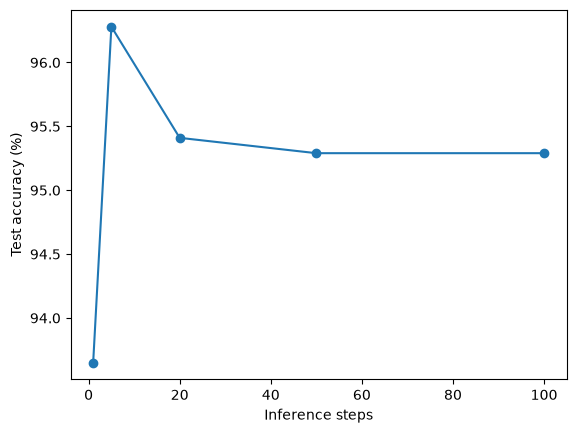

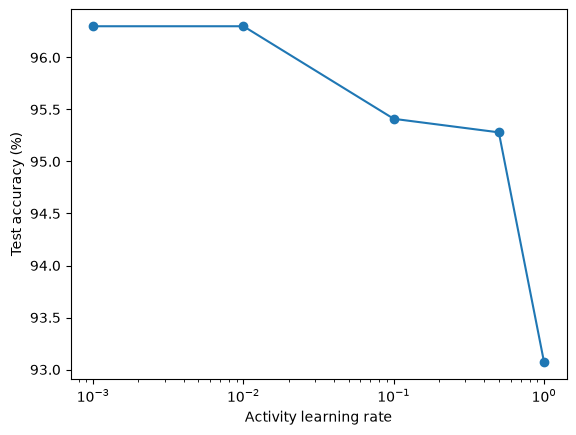

In [26]:
step_results = []
lr_results = []

for steps, lr, accuracy in results:
    if lr == 0.1:
        step_results.append((steps, accuracy))
    if steps == 20:
        lr_results.append((lr, accuracy))

step_results.sort()
lr_results.sort()

fig, ax = plt.subplots()
ax.plot(
    [r[0] for r in step_results],
    [r[1] for r in step_results],
    "o-"
)
ax.set_xlabel("Inference steps")
ax.set_ylabel("Test accuracy (%)")
plt.show()

fig, ax = plt.subplots()
ax.plot(
    [r[0] for r in lr_results],
    [r[1] for r in lr_results],
    "o-"
)
ax.set_xscale("log")
ax.set_xlabel("Activity learning rate")
ax.set_ylabel("Test accuracy (%)")
plt.show()